# **Problem Statement**

## Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

## Objective

“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data of generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators could be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model. These will result in repairing costs.
- False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
- False positives (FP) are detections where there is no failure. These will result in inspection costs.

It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variables should be considered as “failure” and “0” represents “No failure”.

## Data Description

The data provided is a transformed version of the original data which was collected using sensors.

- Train.csv - To be used for training and tuning of models.
- Test.csv - To be used only for testing the performance of the final best model.

Both the datasets consist of 40 predictor variables and 1 target variable.

# **Installing and Importing the necessary libraries**

In [1]:
# Run once, then restart the kernel / runtime and run the remaining cells in order.
# TensorFlow 2.18 needs Python 3.9-3.12.
%pip install -q tensorflow==2.18.0 scikit-learn==1.3.2 matplotlib==3.8.3 seaborn==0.13.2 numpy==1.26.4 pandas==2.2.2

ERROR: Could not find a version that satisfies the requirement tensorflow==2.18.0 (from versions: 2.20.0rc0, 2.20.0, 2.21.0rc0, 2.21.0rc1, 2.21.0, 2.22.0rc0)
ERROR: No matching distribution found for tensorflow==2.18.0


Note: you may need to restart the kernel to use updated packages.


**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, classification_report,
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input

In [3]:
SEED = 812
# Seeds numpy, python and the backend; op determinism makes runs repeatable (a little slower).
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

# **Loading the Data**

In [4]:
# Put Train.csv and Test.csv next to this notebook, or set DATA_DIR.
DATA_DIR = os.environ.get("DATA_DIR", ".")
train_raw = pd.read_csv(os.path.join(DATA_DIR, "Train.csv"))
test_raw = pd.read_csv(os.path.join(DATA_DIR, "Test.csv"))

df = train_raw.copy()
df_test = test_raw.copy()

# **Data Overview**

In [5]:
df.head(10)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,-5.714719,0.735893,0.981251,1.417884,-3.375815,-3.047303,0.306194,2.914097,2.269979,4.394876,-2.388299,0.646388,-1.190508,3.132986,0.665277,-2.510846,-0.036744,0.726218,-3.982187,-1.072638,1.667098,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,1.914465,-0.951458,-1.255259,-2.706522,0.193223,-4.769379,-2.205319,0.907716,0.756894,-5.833678,-3.065122,1.596647,-1.757311,1.766444,-0.267098,3.625036,1.500346,-0.585712,0.783034,-0.201217,0.024883,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,-0.770673,1.106718,1.144261,0.943301,-3.163804,-4.247825,-4.038909,3.688534,3.311196,1.059002,-2.143026,1.650120,-1.660592,1.679910,-0.450782,-4.550695,3.738779,1.134404,-2.033531,0.840839,-1.600395,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,-3.053023,0.459719,2.704527,-0.636086,-0.453717,-3.174046,-3.404347,-1.281536,1.582104,-1.951778,-3.516555,-1.206011,-5.627854,-1.817653,2.124142,5.294642,4.748137,-2.308536,-3.962977,-6.028730,4.948770,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,1.998347,4.723757,0.709113,-1.989432,-2.632684,4.184447,2.245356,3.734452,-6.312766,-5.379918,-0.886667,2.061694,9.445586,4.489976,-3.945144,4.582065,-8.780422,-3.382967,5.106507,6.787513,2.044184,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0
5,0.159623,-4.233781,-0.264310,-5.477119,-0.190854,-0.356274,-0.134486,4.066608,-3.858569,1.692441,0.137901,3.974719,0.672853,1.878144,0.764158,4.235913,-2.129272,2.348465,-2.147454,-0.982376,0.386345,1.010637,3.418654,0.996017,0.060580,-3.036740,1.787573,-1.726537,0.307837,1.902350,4.665858,3.227235,0.628900,-1.548860,1.321979,5.461345,1.109410,-3.869993,0.273964,2.805941,0
6,-0.184565,-4.721470,0.864988,-3.078695,-2.226888,-1.282220,-0.804717,3.289733,-1.567971,0.749904,0.528830,3.220564,2.945183,1.724073,-0.923123,2.534830,-1.696713,0.677068,-0.246087,2.747678,-1.165392,0.247621,1.160684,-2.850139,0.503405,-3.532215,1.861243,-1.465354,0.873767,2.418470,0.939376,-0.544941,-0.762921,0.815558,1.889373,3.624347,1.555740,-5.432884,0.678703,0.464697,0
7,1.734840,1.682945,-1.269070,4.600630,-1.416975,-2.543916,0.131648,-0.198661,3.094057,-1.109324,-1.662364,0.943806,3.481045,0.137055,-3.472977,-4.075917,1.726571,-1.908618,3.569249,2.512191,-4.578679,3.062674,3.686149,0.610743,-0.429539,0.880126,-0.993851,1.134221,-3.767917,-0.692236,-5.244396,1.717474,-3.838931,1.569448,1.794899,-4.268517,-0.516195,-0.619218,-0.830889,-4.967266,1
8,1.781583,1.314664,4.248690,-0.518293,-0.149044,0.033082,-1.087893,-3.117561,0.624935,1.567455,-0.415122,-1.400792,2.607063,-1.023519,-2.877902,-4.524080,-4.353952,0.106859,1.298601,-3.595654,-5.409204,0.633421,-3.043436,0.965268,-0.266332,4.670862,1.846717,-2.320822,-1.317705,-0.681722,3.280787,1.611014,2.951390,-1.862016,4.389598,1.371300,-2.516235,0.770496,0.831132,-2.310953,0
9,-0.894140,4.011498,5.251902,3.320747,0.727067,-4.771070,1.031232,3.632080,-1.391444,-1.966746,-4.779273,6.616781,-0.147815,-2.513234,0.734111,0.474710,5.085254,-2.360998,4.561398,2.287065,-2.307024,-0.948690,-0.300906,2.546197,0.738320,4.266330,-4.144926,-0.012559,-1.469495,-2.003484,1.680064,-0.635742,-4.449139,2.296340,1.575110,1.376268,0.596757,-1.413652,0.543871,0.035020,0


In [6]:
df.tail(10)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,V29,V30,V31,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
19990,-0.579836,-2.629670,0.474419,-2.671421,-2.323783,-1.830285,-0.112126,3.581327,-1.085178,-1.369451,1.767417,6.224762,5.042030,0.400828,-2.542281,2.449718,-1.428508,0.166265,0.522199,2.209299,-2.433586,0.556661,2.734731,-3.876636,-0.718225,-1.493686,0.255552,-2.086910,1.982364,3.622774,-1.734806,-1.940408,-0.769011,0.802292,1.814545,1.657435,2.424586,-4.565140,0.827243,0.228813,0
19991,6.826134,3.141716,6.575012,-4.684994,-1.978555,1.552752,1.268366,-5.975145,0.297224,2.047525,1.804079,1.135324,1.668978,-3.104414,0.619022,-7.283990,-6.666338,-0.155940,3.029251,-7.245370,-7.165591,1.510670,-6.424466,-2.026136,2.080010,5.324239,8.179894,-2.789136,-0.921318,-3.272047,2.875938,-7.818127,0.765248,-0.539477,4.031437,2.270127,-2.454773,5.460646,2.018346,0.081557,0
19992,-0.730383,-8.463166,1.111823,-8.918874,-2.309441,2.902515,-4.203021,-3.019003,-0.093653,2.472905,0.468690,-1.062925,5.313560,2.043371,-6.505954,-5.233454,-6.589395,8.245479,-5.011889,0.658846,-5.277002,2.836614,-0.947907,-4.253186,0.860204,-4.562051,5.660413,-3.458896,0.611588,3.127485,0.417374,-2.711114,3.624536,-3.264870,2.393250,7.795103,2.312051,-3.950337,3.226444,1.138433,0
19993,0.250887,-5.068987,5.866389,-5.048788,-1.226417,-2.077842,-3.638690,0.940573,0.851951,0.056203,-5.854509,1.205419,5.853582,1.681216,-5.514426,-4.292434,-0.950994,5.338832,-3.948433,4.647299,-6.620145,1.576410,-1.265721,-4.026239,3.237762,-0.598316,2.815635,-3.942490,-2.896285,-1.506242,3.623994,-2.642109,-2.768446,-2.611676,1.853566,9.387797,2.556526,-9.389720,2.845682,1.878341,0
19994,-2.546629,-2.370481,-0.728626,-0.947777,1.417739,-2.489878,-0.820629,4.790304,-2.949182,0.209342,-4.884580,4.837842,-0.586480,1.125590,-1.009470,1.744349,3.863306,3.287753,-0.641372,2.603885,-0.275286,2.109980,5.816237,5.163208,-0.078063,-2.389215,-3.367774,0.463266,-2.438445,0.592484,2.047696,5.798262,-2.451336,-0.697349,0.460678,4.298600,1.973705,-3.613722,0.165335,1.342830,0
19995,-2.071318,-1.088279,-0.796174,-3.011720,-2.287540,2.807310,0.481428,0.105171,-0.586599,-2.899398,8.868415,1.717155,1.357838,-1.777135,0.709780,4.944939,-3.100454,-1.199228,-1.084629,-0.365044,3.131175,-3.948103,-3.578469,-8.139067,-1.936861,-1.327691,-0.402688,-1.734796,9.996461,6.955367,-3.938493,-8.273996,5.745013,0.589014,-0.649988,-3.043174,2.216461,0.608723,0.178193,2.927755,1
19996,2.890264,2.483069,5.643919,0.937053,-1.380870,0.412051,-1.593386,-5.762498,2.150096,0.272302,-2.094760,-1.525834,0.071573,-3.540142,-2.762006,-10.632206,-0.495236,1.720074,3.871596,-1.209610,-8.222073,2.120866,-5.491808,1.452340,1.450002,3.684654,1.076760,-0.384175,-0.838593,-0.748275,-1.088553,-4.159092,1.181466,-0.742412,5.368979,-0.693028,-1.668971,3.659954,0.819863,-1.987265,0
19997,-3.896979,-3.942407,-0.351364,-2.417462,1.107546,-1.527623,-3.519882,2.054792,-0.233996,-0.357687,-3.781972,2.180042,6.111780,1.984747,-8.330002,-1.639184,-0.914960,5.672348,-3.924200,2.133196,-4.502031,2.777178,5.727949,1.619818,-1.699691,-0.041882,-2.923094,-2.760158,-2.253766,2.552033,0.981858,7.112162,1.476080,-3.953710,1.855555,5.029209,2.082588,-6.409304,1.477138,-0.874148,0
19998,-3.187322,-10.051662,5.695955,-4.370053,-5.354758,-1.873044,-3.947210,0.679420,-2.389254,5.456756,1.583029,3.571478,9.226573,2.553587,-7.039109,-0.993573,-9.664938,1.155224,3.876895,3.523634,-7.015329,-0.132037,-3.446179,-4.801443,-0.875727,-3.811854,5.422077,-3.732322,0.608811,5.256460,1.914766,0.402812,3.163661,3.752095,8.529894,8.450626,0.203958,-7.129918,4.249394,-6.112267,0
19999,-2.686903,1.961187,6.137088,2.600133,2.657241,-4.290882,-2.344267,0.974004,-1.027462,0.497421,-9.589075,3.176560,1.054517,-1.415882,-4.668611,-5.405377,3.719759,2.892923,2.328591,1.457704,-6.428543,1.818232,0.805897,7.786026,0.330857,5.257424,-4.867417,-0.818941,-5.667393,-2.860975,4.674280,6.620811,-1.988786,-1.348901,3.951801,5.449706,-

In [7]:
df.shape

(20000, 41)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22  V23     2

V1 and V2 each have 18 missing values in the training set (the test set has 5 and 6).

In [9]:
print(df.isna().sum()[lambda s: s > 0])
print(df_test.isna().sum()[lambda s: s > 0])

V1    18
V2    18
dtype: int64
V1    5
V2    6
dtype: int64


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,19982.0,-0.271996,3.441625,-11.876451,-2.737146,-0.747917,1.840112,15.493002
V2,19982.0,0.440430,3.150784,-12.319951,-1.640674,0.471536,2.543967,13.089269
V3,20000.0,2.484699,3.388963,-10.708139,0.206860,2.255786,4.566165,17.090919
V4,20000.0,-0.083152,3.431595,-15.082052,-2.347660,-0.135241,2.130615,13.236381
V5,20000.0,-0.053752,2.104801,-8.603361,-1.535607,-0.101952,1.340480,8.133797
V6,20000.0,-0.995443,2.040970,-10.227147,-2.347238,-1.000515,0.380330,6.975847
V7,20000.0,-0.879325,1.761626,-7.949681,-2.030926,-0.917179,0.223695,8.006091
V8,20000.0,-0.548195,3.295756,-15.657561,-2.642665,-0.389085,1.722965,11.679495
V9,20000.0,-0.016808,2.160568,-8.596313,-1.494973,-0.067597,1.409203,8.137580
V10,20000.0,-0.012998,2.193201,-9.853957,-1.411212,0.100973,1.477045,8.108472


In [11]:
print(f"Duplicate rows in train: {df.duplicated().sum()}")
print(f"Rows in test that also appear in train: {len(df.merge(df_test, how='inner'))}")
print(df["Target"].value_counts())
print(df["Target"].value_counts(normalize=True).round(4))

Duplicate rows in train: 0
Rows in test that also appear in train: 0
Target
0    18890
1     1110
Name: count, dtype: int64
Target
0    0.9445
1    0.0555
Name: proportion, dtype: float64


About 5.55% of the training rows (1,110 of 20,000) are failures, and 5.64% of the test rows. The classes are heavily imbalanced, so accuracy alone is misleading (predicting "no failure" every time scores about 94.5%); the models are judged on recall, precision and F1/F2 for the failure class. No row is duplicated within the training set, and none of the test rows appears in the training set.

In [12]:
both_missing = (df["V1"].isnull() & df["V2"].isnull()).sum()
print(f"Rows where both V1 and V2 are missing: {both_missing}")

Rows where both V1 and V2 are missing: 0


Missing values are limited to V1 and V2 and never occur in the same row. They are filled with the **training-set median** of each column. The median is used because V1 is not symmetric (its mean is -0.27 but its median is -0.75). The imputer is fitted on the training split only and then applied to the validation and test sets: the original notebook filled the training data on the full set before splitting, and left the missing values in the test set, so the 11 test rows with a missing V1 or V2 reached the model as NaN, which makes the network output NaN and those rows were silently predicted as "no failure".

## Univariate analysis

In [13]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins,
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

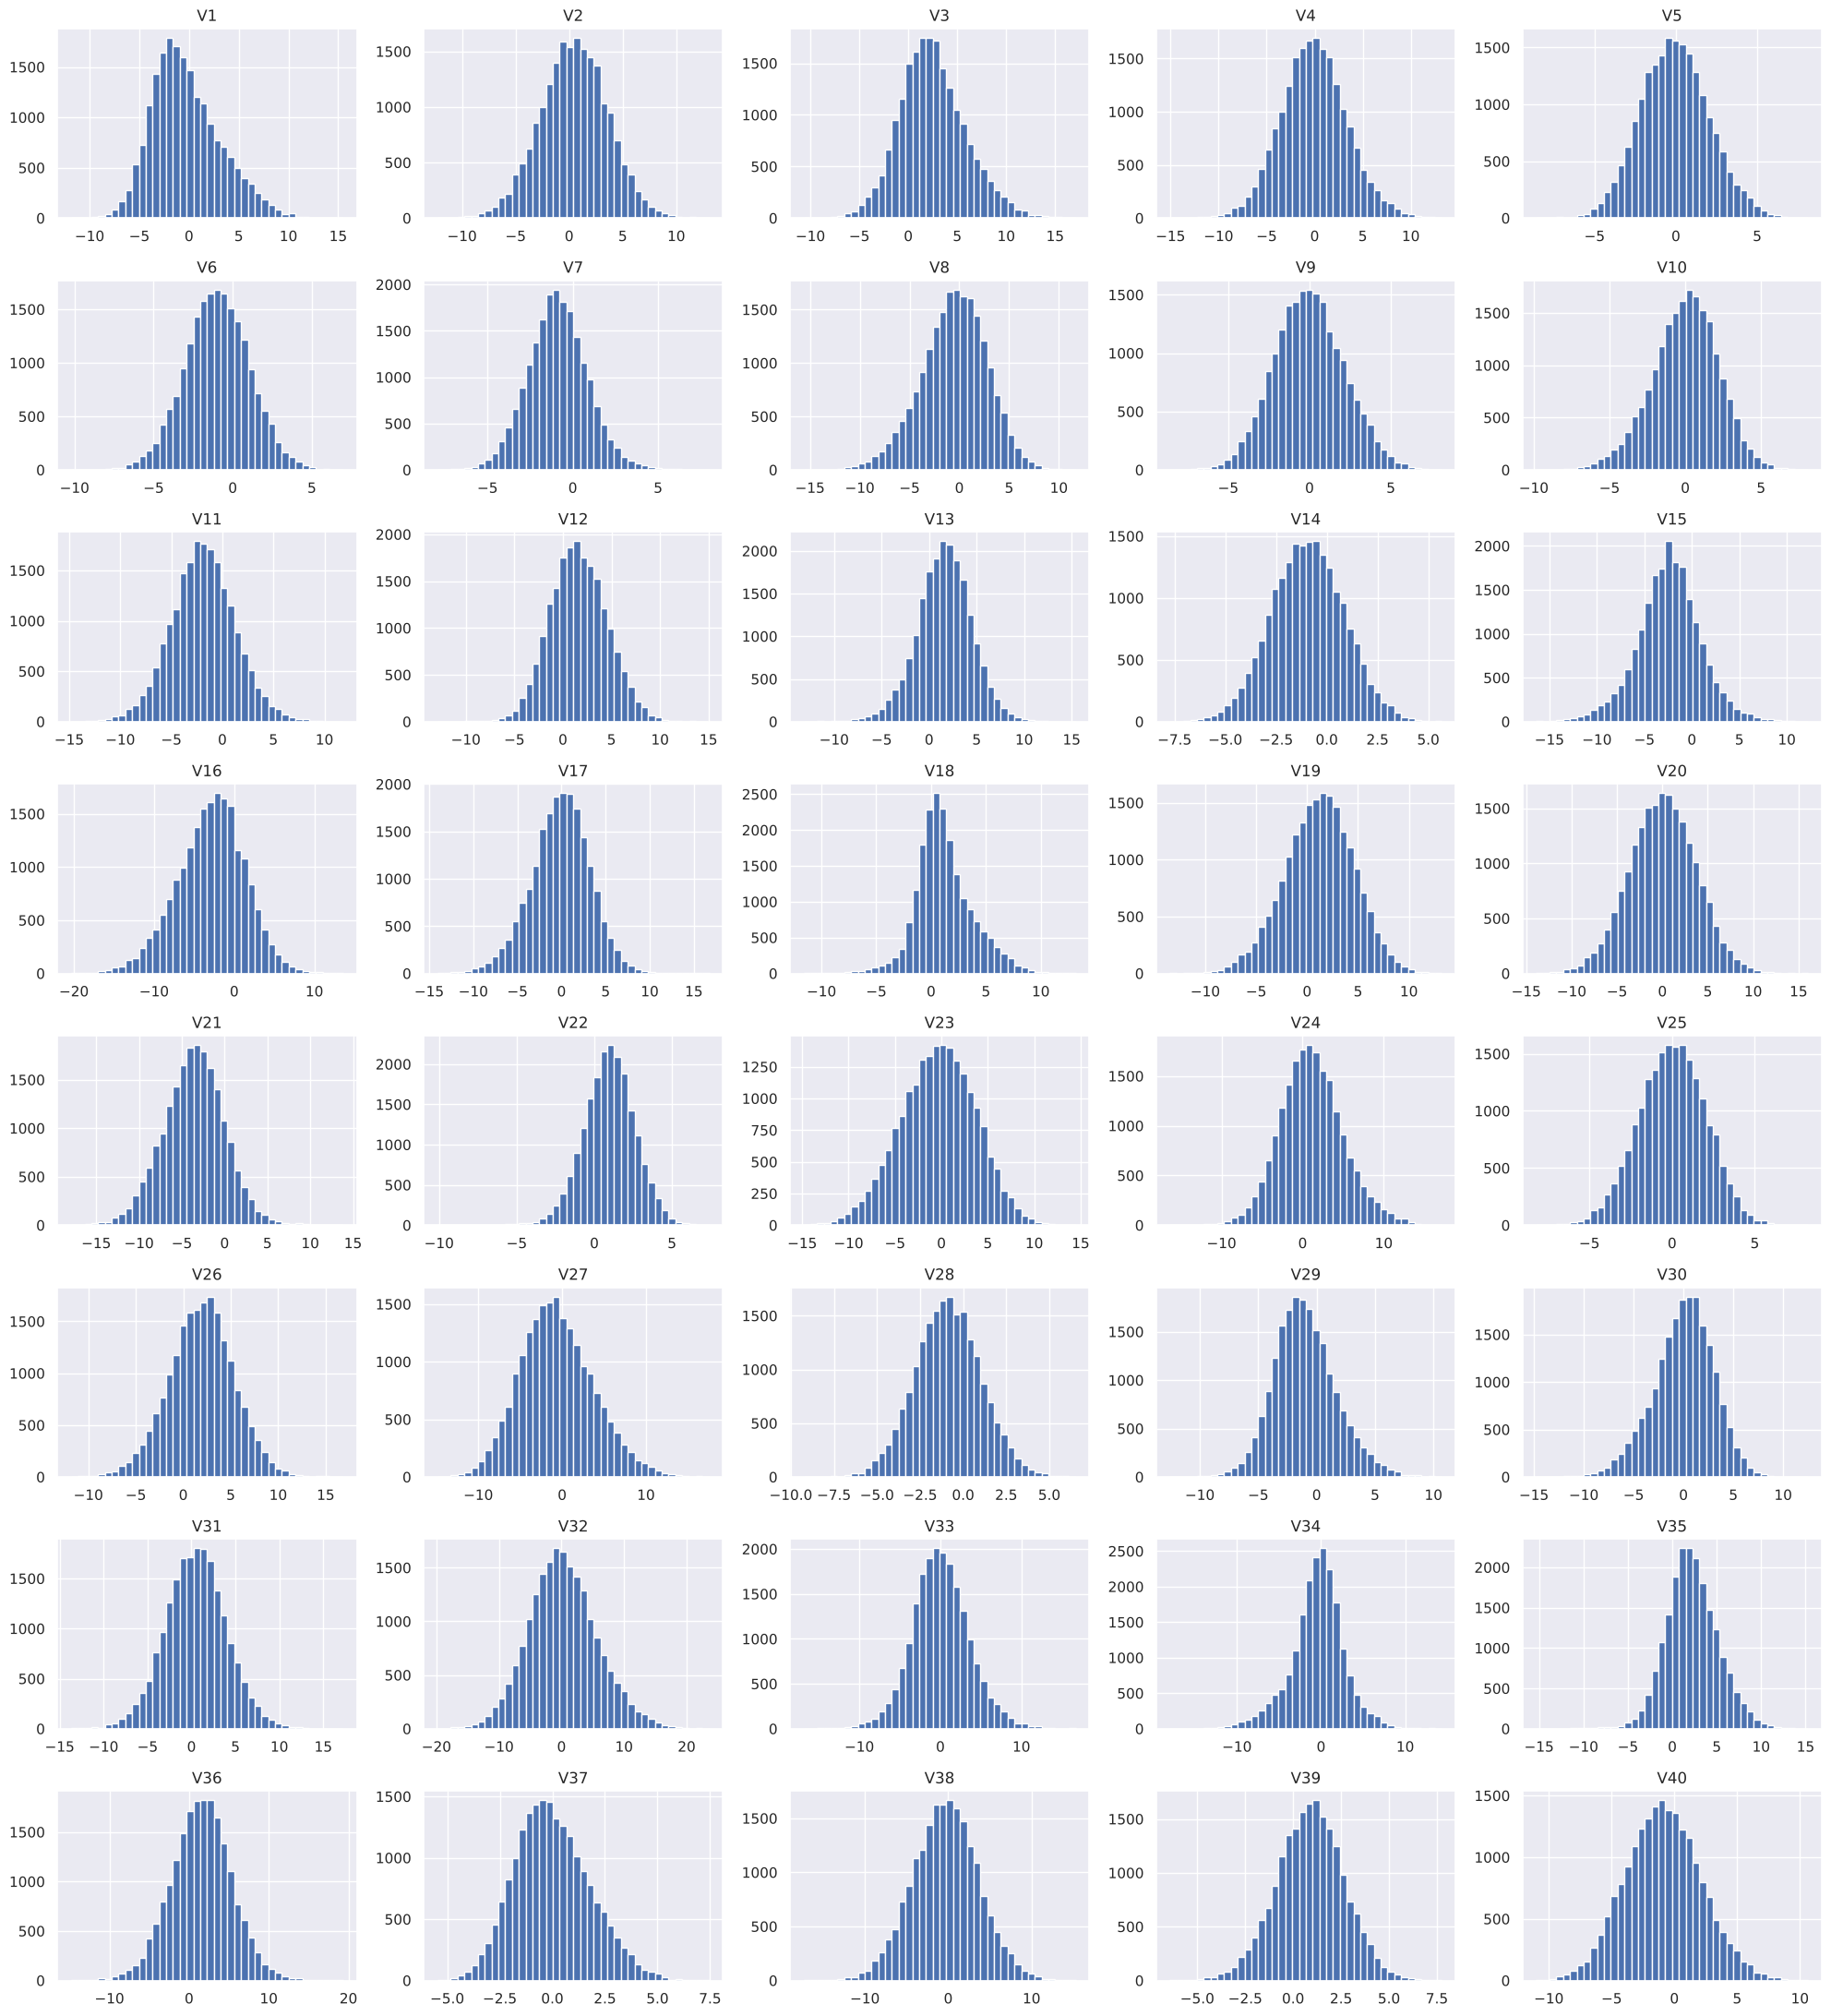

Overall min / max: -20.37 / 23.63


In [14]:
features = [c for c in df.columns if c != "Target"]

fig, axes = plt.subplots(8, 5, figsize=(20, 22))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col].dropna(), bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.show()

print("Overall min / max:", df[features].min().min().round(2), "/", df[features].max().max().round(2))

The 40 predictors are roughly bell-shaped (mild skew, absolute skewness at most about 0.55) and centred near zero; the original notebook called them "uniformly distributed", which they are not. Values run from about -20 to +24 with no obvious data errors, so no outlier treatment is applied.

## Bivariate analysis

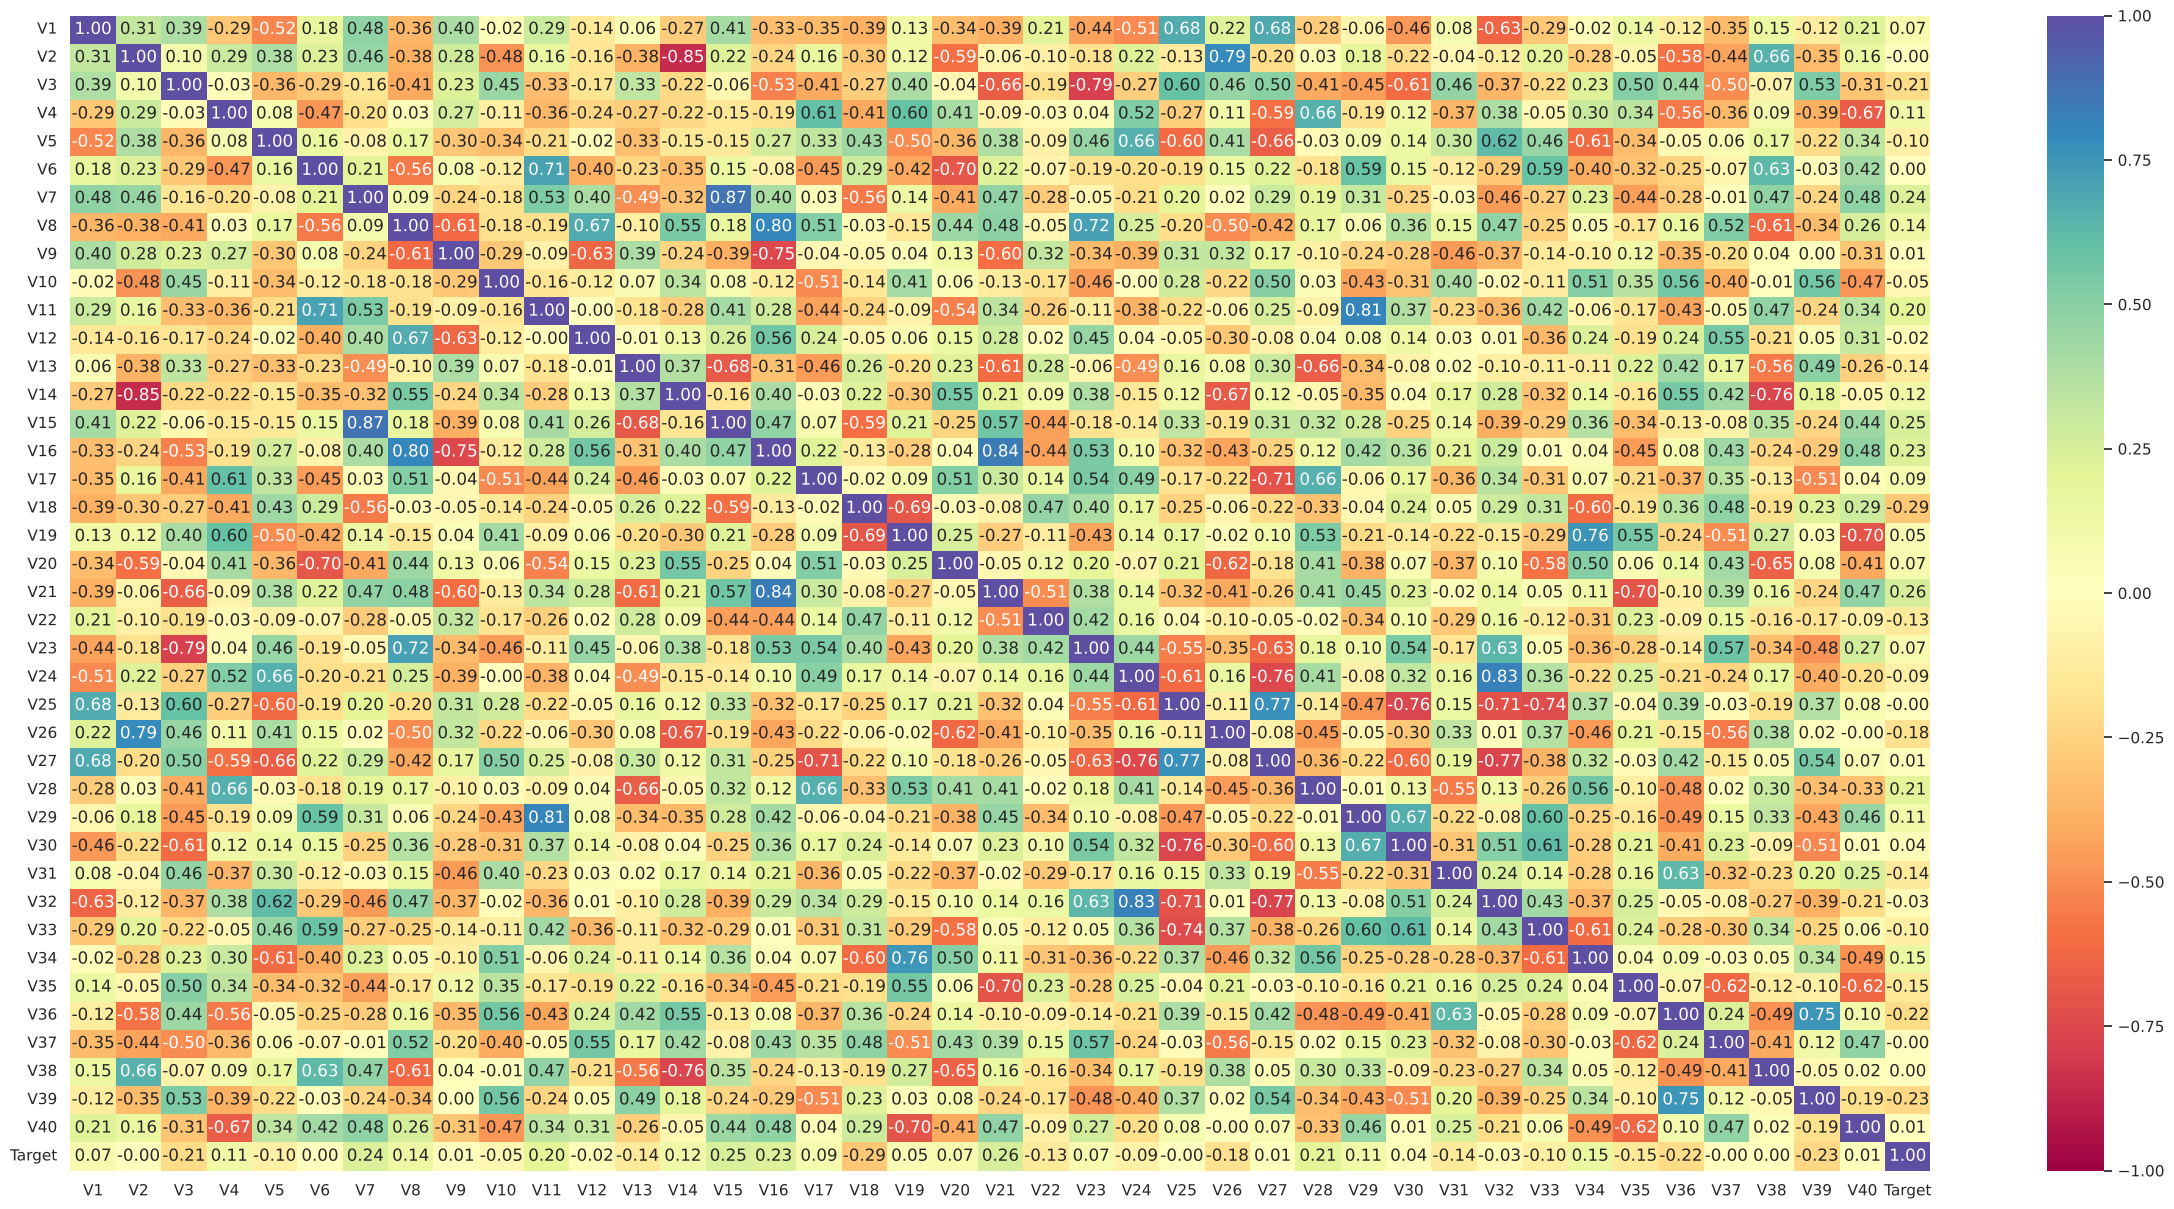

In [15]:
plt.figure(figsize=(30, 15))
sns.heatmap(df.corr(numeric_only=True), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

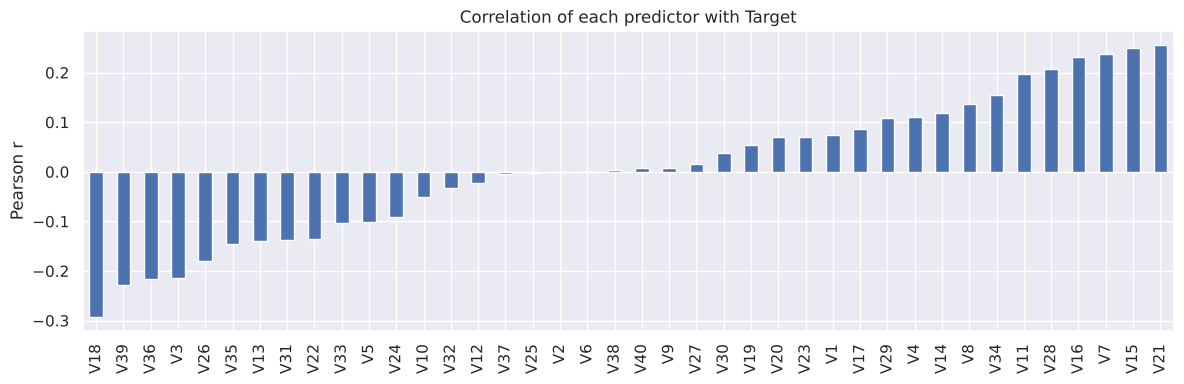

Most negative: {'V18': -0.29, 'V39': -0.23, 'V36': -0.22, 'V3': -0.21, 'V26': -0.18}
Most positive: {'V28': 0.21, 'V16': 0.23, 'V7': 0.24, 'V15': 0.25, 'V21': 0.26}


In [16]:
corr_target = df.corr()["Target"].drop("Target").sort_values()
plt.figure(figsize=(12, 4))
corr_target.plot(kind="bar")
plt.title("Correlation of each predictor with Target")
plt.ylabel("Pearson r")
plt.tight_layout()
plt.show()
print("Most negative:", corr_target.head(5).round(2).to_dict())
print("Most positive:", corr_target.tail(5).round(2).to_dict())

No single predictor correlates strongly with failure. The strongest positive correlations are with V21, V15, V7, V16 and V28 (about 0.21-0.26) and the strongest negative with V18, V39, V36 and V3 (about -0.21 to -0.29). Any useful signal therefore comes from combinations of sensors, which is why a neural network is used.

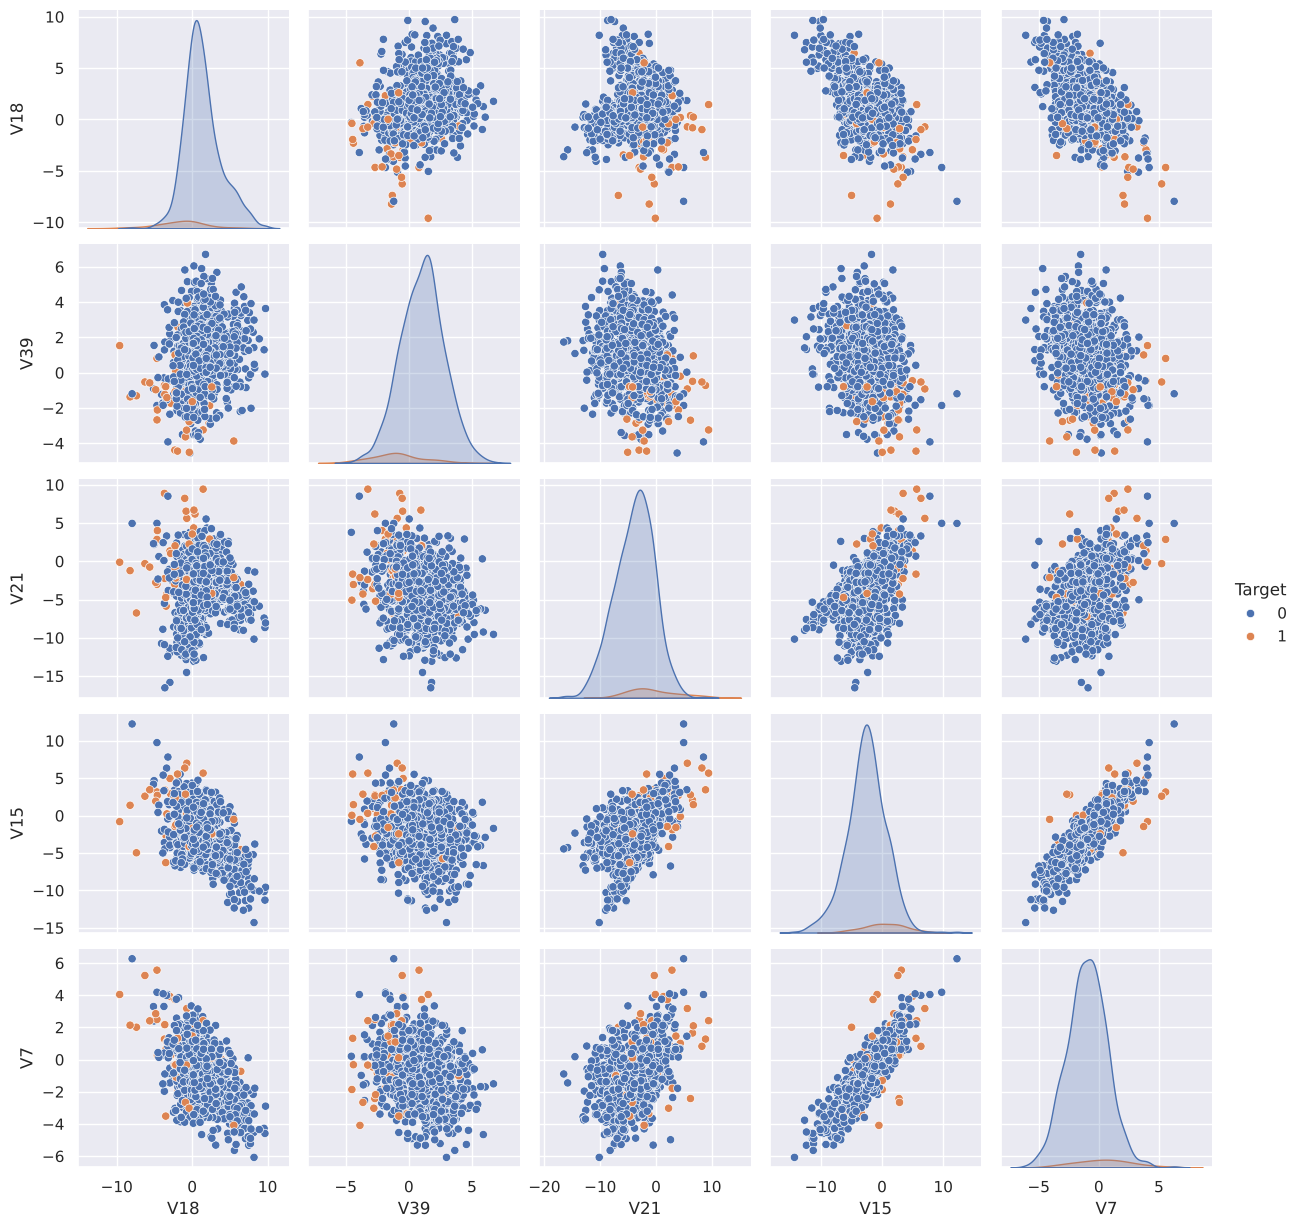

In [17]:
sns.pairplot(data=df.sample(1000, random_state=SEED)[["V18", "V39", "V21", "V15", "V7", "Target"]], hue="Target")
plt.show()

In [18]:
### function to plot distributions wrt target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
        bins = 20,
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
        bins = 20,
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

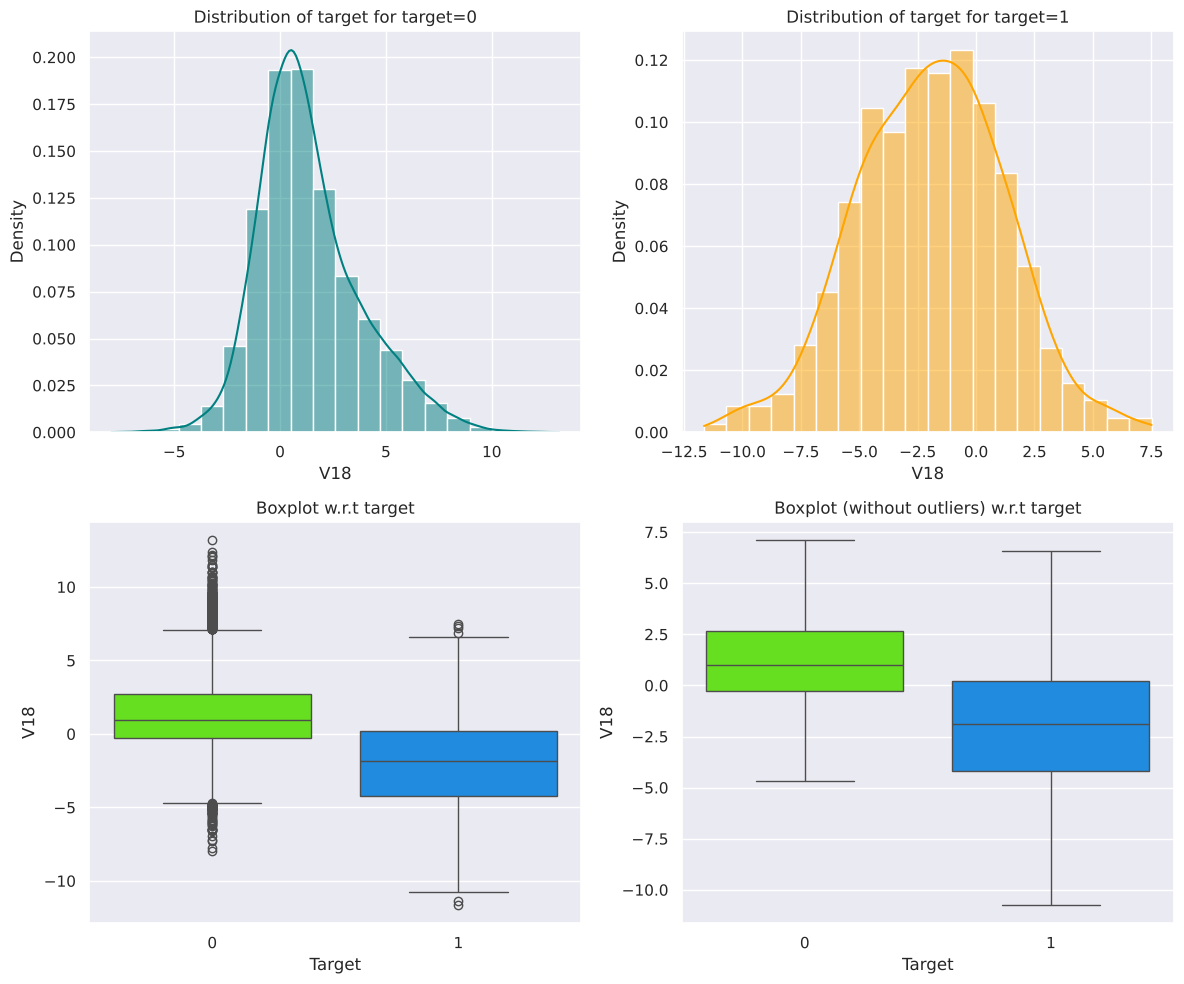

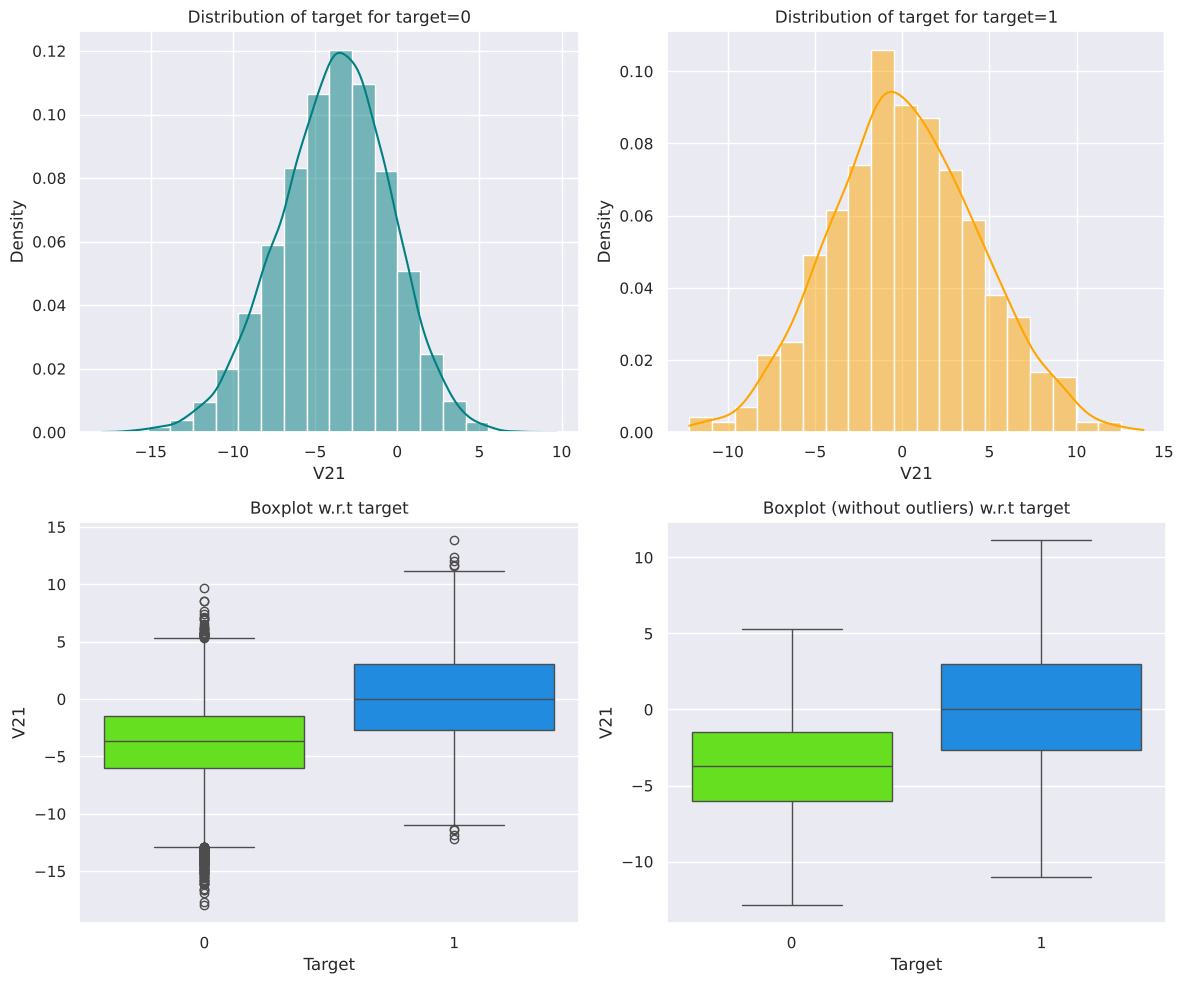

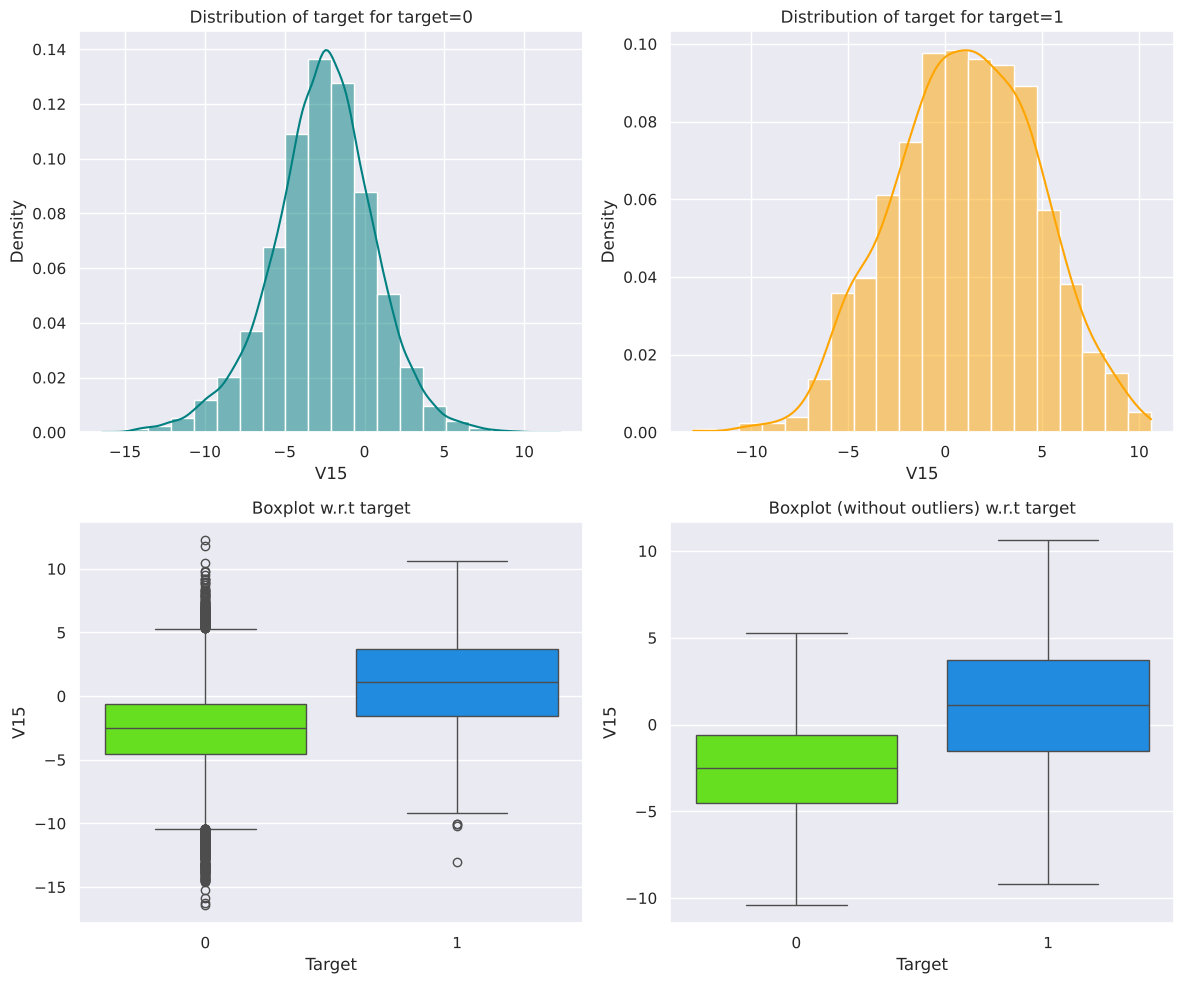

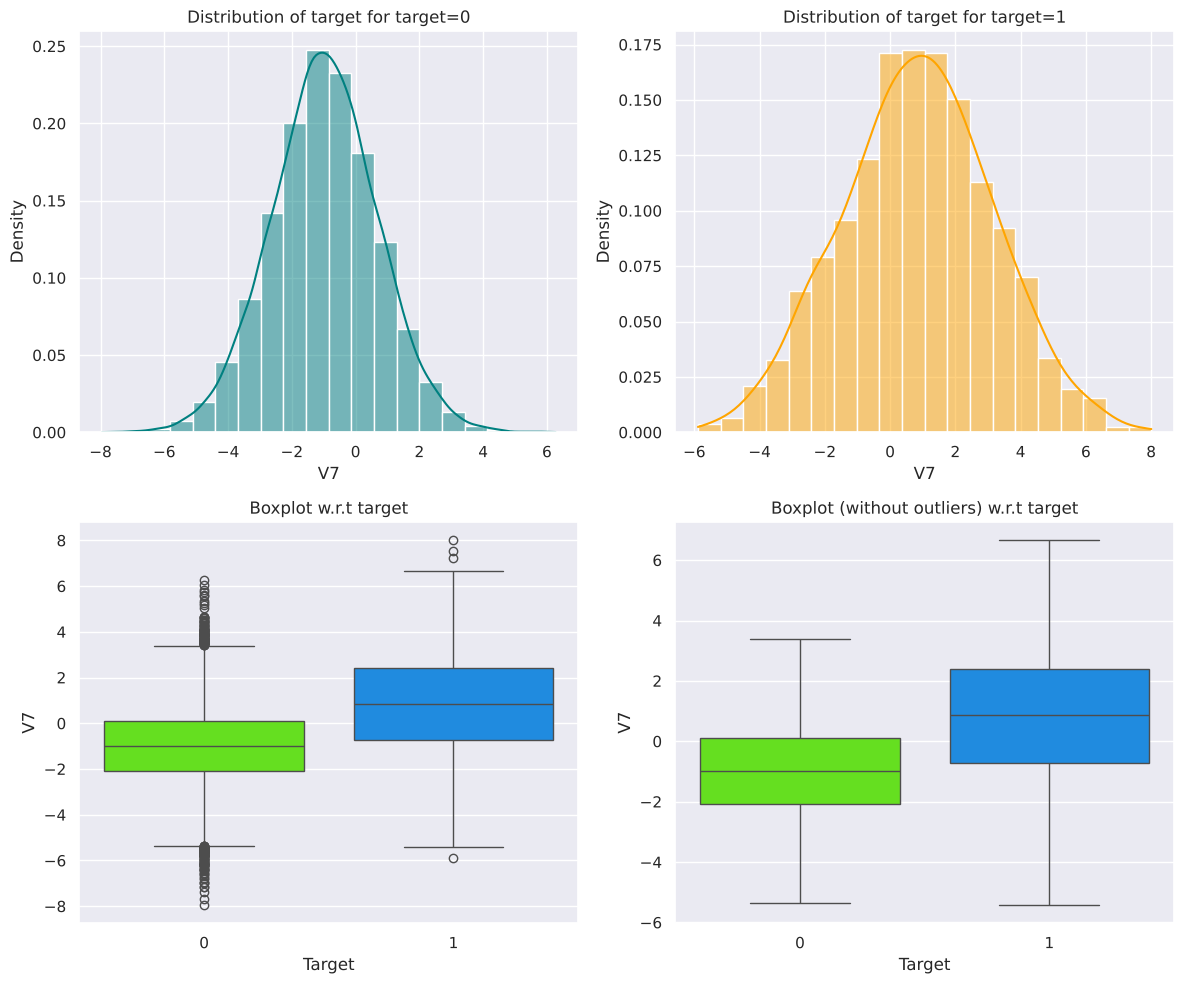

In [19]:
top = corr_target.abs().sort_values(ascending=False).head(4).index
for col in top:
    distribution_plot_wrt_target(df, col, "Target")

For the most correlated predictors the failure class (Target = 1) is shifted relative to the non-failure class, but the two distributions overlap heavily. This is consistent with the modest correlations above.

# **Data Preprocessing**

In [20]:
X = df.drop("Target", axis=1)
y = df["Target"]

# 75 / 25 train / validation split, stratified so both keep the 5.55% failure rate
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
X_test = df_test.drop("Target", axis=1)
y_test = df_test["Target"]

# Impute with the training median, then scale to [0, 1]. Both are fitted on the training split only.
imputer = SimpleImputer(strategy="median").fit(X_train)
X_train, X_val, X_test = (imputer.transform(a) for a in (X_train, X_val, X_test))

scaler = MinMaxScaler().fit(X_train)
X_train, X_val, X_test = (scaler.transform(a) for a in (X_train, X_val, X_test))

print("NaNs left:", int(np.isnan(X_train).sum() + np.isnan(X_val).sum() + np.isnan(X_test).sum()))
for name, a in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test), ("y_train", y_train), ("y_val", y_val), ("y_test", y_test)]:
    print(name, a.shape)

NaNs left: 0
X_train (15000, 40)
X_val (5000, 40)
X_test (5000, 40)
y_train (15000,)
y_val (5000,)
y_test (5000,)


# **Model Building**

## Model Evaluation Criterion

Target = 1 is a failure. The costs are ordered: **replacing** a generator (a missed failure, false negative) costs far more than **repairing** one (true positive), which costs more than an **inspection** (false positive). The aim is therefore a high **recall** on failures while keeping false alarms reasonable.

The exact costs are not given, so the models are compared on validation **recall**, **precision** and **F2**. F2 is the F-score that counts recall twice as heavily as precision, a reasonable stand-in for "missing a failure is worse than an extra inspection". The final model is the one with the highest validation F2. The test set is used only once, for that model.

In [21]:
def plot(history, name):
    """Plot a training metric and its validation counterpart (name: 'loss', 'recall', ...)."""
    plt.figure(figsize=(6, 4))
    plt.plot(history.history[name])
    plt.plot(history.history["val_" + name])
    plt.title("Model " + name.capitalize())
    plt.ylabel(name.capitalize())
    plt.xlabel("Epoch")
    plt.legend(["Train", "Validation"], loc="best")
    plt.show()


def metrics(model, X, y, threshold=0.5):
    """Accuracy / precision / recall / F1 / F2 of the failure class at the given threshold."""
    pred = (model.predict(X, verbose=0).ravel() > threshold).astype("int32")
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred, zero_division=0),
        "f2": fbeta_score(y, pred, beta=2, zero_division=0),
    }

All six architectures below are trained twice, once as is and once with **class weights** (the failure class is weighted about 9x the non-failure class). Every model uses the same 50 epochs and batch size 64, the same seed, and is evaluated with the same function on the training and validation sets. The original notebook mixed two ways of computing the training metrics (last-epoch running values from Keras for some models, a fresh pass over the data for others), typed one result in by hand, and mislabelled Model 2 as having two hidden layers although it has one; this version records every model the same way.

In [22]:
classes = np.unique(y_train)
weights = class_weight.compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weight_dict)

Class weights: {0: 0.5293993082515706, 1: 9.003601440576231}


### The six architectures

| Model | Hidden layers | Optimiser | Regularisation |
|---|---|---|---|
| 0 | [14] ReLU | SGD | none |
| 1 | [14] ReLU | SGD, momentum 0.9 | none |
| 2 | [14] ReLU | Adam | none |
| 3 | [28, 14] ReLU | Adam | Dropout 0.3 after each hidden layer |
| 4 | [28, 14] ReLU | Adam | Batch normalisation after each hidden layer |
| 5 | [28, 14] ReLU | Adam | Batch normalisation + Dropout 0.05 after each hidden layer |

(The original unweighted Model 5 used dropout 0.05 and 0.15 and the weighted one 0.05 and 0.05; both now use 0.05 so each pair differs only in the class weights.)

In [23]:
def build_model(arch, n_features):
    """Build and compile one of the six architectures."""
    model = Sequential([Input(shape=(n_features,))])
    if arch == 3:
        model.add(Dense(28, activation="relu")); model.add(Dropout(0.3))
        model.add(Dense(14, activation="relu")); model.add(Dropout(0.3))
    elif arch == 4:
        model.add(Dense(28, activation="relu")); model.add(BatchNormalization())
        model.add(Dense(14, activation="relu")); model.add(BatchNormalization())
    elif arch == 5:
        model.add(Dense(28, activation="relu")); model.add(BatchNormalization()); model.add(Dropout(0.05))
        model.add(Dense(14, activation="relu")); model.add(BatchNormalization()); model.add(Dropout(0.05))
    else:                                   # architectures 0, 1, 2: one hidden layer of 14
        model.add(Dense(14, activation="relu"))
    model.add(Dense(1, activation="sigmoid"))

    optimizer = {
        0: keras.optimizers.SGD(),
        1: keras.optimizers.SGD(momentum=0.9),
    }.get(arch, keras.optimizers.Adam())

    model.compile(
        loss="binary_crossentropy",
        optimizer=optimizer,
        metrics=[
            keras.metrics.Recall(name="recall"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.BinaryAccuracy(name="binary_accuracy"),
        ],
    )
    return model


ARCH_INFO = {
    0: ("1", "[14]", "SGD"),
    1: ("1", "[14]", "SGD (momentum 0.9)"),
    2: ("1", "[14]", "Adam"),
    3: ("2", "[28, 14]", "Adam, Dropout(0.3)"),
    4: ("2", "[28, 14]", "Adam, BatchNorm"),
    5: ("2", "[28, 14]", "Adam, BatchNorm, Dropout(0.05)"),
}
EPOCHS = 50
BATCH_SIZE = 64

evaluation_results = []
models, histories = {}, {}


def train_and_log(arch, weighted):
    """Train one model, evaluate it on train and validation, and log the result."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)           # same starting point for every model
    model = build_model(arch, X_train.shape[1])
    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        batch_size=BATCH_SIZE, epochs=EPOCHS, verbose=0,
        class_weight=class_weight_dict if weighted else None,
    )
    seconds = time.time() - start
    tr, va = metrics(model, X_train, y_train), metrics(model, X_val, y_val)
    layers, neurons, config = ARCH_INFO[arch]
    name = f"Model {arch}" + (" (Weighted)" if weighted else "")
    evaluation_results.append({
        "Model": name, "# hidden layers": layers, "neurons": neurons, "configuration": config,
        "class weights": weighted, "# epochs": EPOCHS, "batch size": BATCH_SIZE,
        "Train_Loss": history.history["loss"][-1],
        "Train_Accuracy": tr["accuracy"], "Train_Precision": tr["precision"], "Train_Recall": tr["recall"], "Train_F1": tr["f1"],
        "Val_Loss": history.history["val_loss"][-1],
        "Val_Accuracy": va["accuracy"], "Val_Precision": va["precision"], "Val_Recall": va["recall"], "Val_F1": va["f1"], "Val_F2": va["f2"],
        "Seconds": round(seconds, 1),
    })
    models[name], histories[name] = model, history
    print(f"{name:20s} val recall={va['recall']:.3f}  precision={va['precision']:.3f}  F2={va['f2']:.3f}  ({seconds:.0f}s)")

## Models 0-5 without class weights

**Model 0** is the baseline: one hidden layer of 14 ReLU units trained with plain SGD. **Model 1** adds momentum. **Model 2** switches to Adam. **Model 3** has two hidden layers with dropout, **Model 4** two hidden layers with batch normalisation, and **Model 5** combines batch normalisation with light dropout.

In [24]:
for arch in range(6):
    train_and_log(arch, weighted=False)

Model 0              val recall=0.310  precision=0.878  F2=0.357  (24s)


Model 1              val recall=0.477  precision=0.863  F2=0.523  (26s)


Model 2              val recall=0.621  precision=0.961  F2=0.668  (26s)


Model 3              val recall=0.747  precision=0.986  F2=0.785  (29s)


Model 4              val recall=0.859  precision=0.979  F2=0.881  (31s)


Model 5              val recall=0.812  precision=0.966  F2=0.839  (35s)


## Models 0-5 with class weights

The same six models, trained with the class weights computed above, which makes a missed failure about 9 times as costly in the loss as a false alarm. This pushes the models toward higher recall.

In [25]:
for arch in range(6):
    train_and_log(arch, weighted=True)

Model 0 (Weighted)   val recall=0.870  precision=0.353  F2=0.673  (26s)


Model 1 (Weighted)   val recall=0.866  precision=0.619  F2=0.802  (26s)


Model 2 (Weighted)   val recall=0.848  precision=0.493  F2=0.741  (27s)


Model 3 (Weighted)   val recall=0.881  precision=0.868  F2=0.878  (30s)


Model 4 (Weighted)   val recall=0.899  precision=0.713  F2=0.854  (33s)


Model 5 (Weighted)   val recall=0.910  precision=0.851  F2=0.897  (37s)


## Learning curves

Model 0


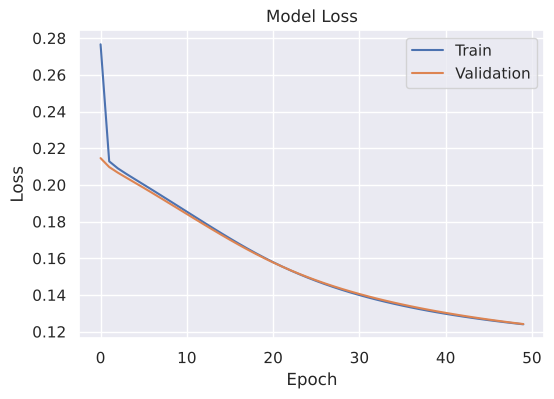

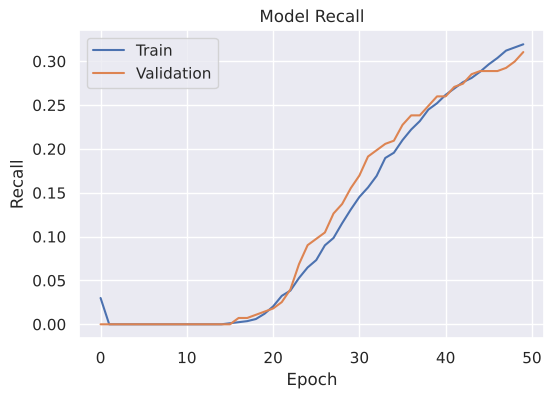

Model 4


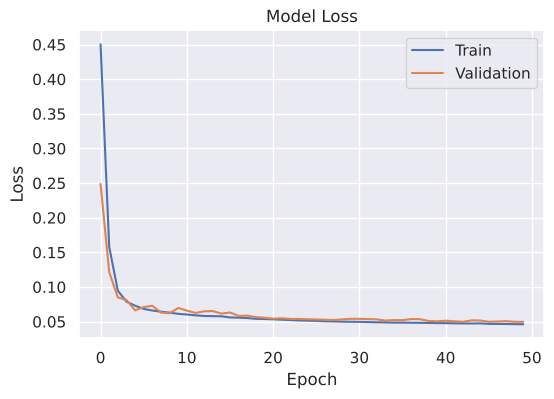

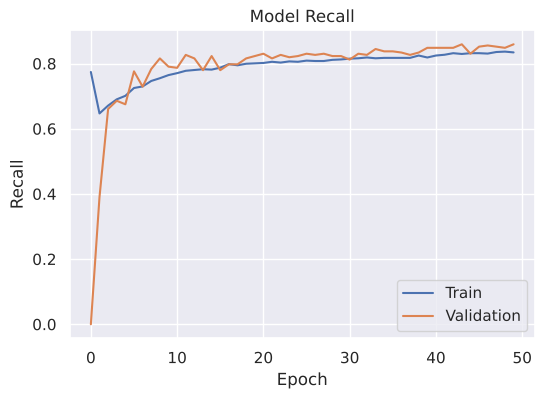

Model 4 (Weighted)


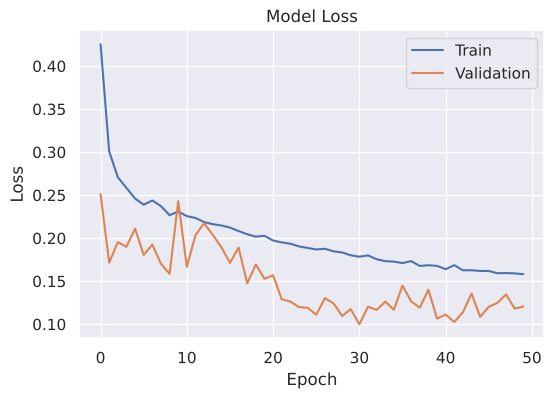

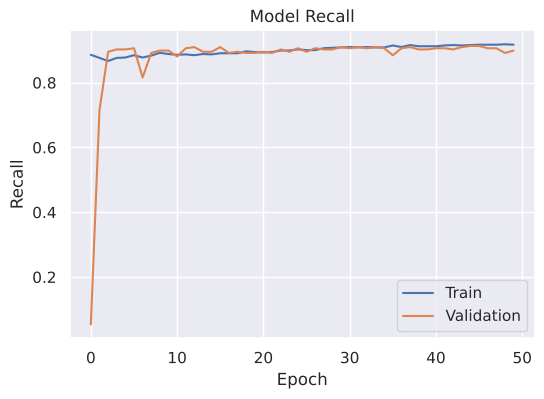

In [26]:
for name in ["Model 0", "Model 4", "Model 4 (Weighted)"]:
    print(name)
    plot(histories[name], "loss")
    plot(histories[name], "recall")

# **Model Performance Comparison and Final Model Selection**

In [27]:
results = pd.DataFrame(evaluation_results)
display(results.sort_values("Val_F2", ascending=False).reset_index(drop=True))

,Model,# hidden layers,neurons,configuration,class weights,# epochs,batch size,Train_Loss,Train_Accuracy,Train_Precision,Train_Recall,Train_F1,Val_Loss,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Val_F2,Seconds
0,Model 5 (Weighted),2,"[28, 14]","Adam, BatchNorm, Dropout(0.05)",True,50,64,0.199866,0.984800,0.832053,0.909964,0.869266,0.107992,0.9862,0.851351,0.909747,0.879581,0.897436,36.6
1,Model 4,2,"[28, 14]","Adam, BatchNorm",False,50,64,0.046135,0.990467,0.977839,0.847539,0.908039,0.049633,0.9912,0.979424,0.859206,0.915385,0.880829,31.4
2,Model 3 (Weighted),2,"[28, 14]","Adam, Dropout(0.3)",True,50,64,0.251025,0.984133,0.853746,0.861945,0.857826,0.139271,0.9860,0.868327,0.880866,0.874552,0.878330,29.7
3,Model 4 (Weighted),2,"[28, 14]","Adam, BatchNorm",True,50,64,0.158151,0.976133,0.730807,0.902761,0.807734,0.120552,0.9744,0.713467,0.898917,0.795527,0.854496,33.3
4,Model 5,2,"[28, 14]","Adam, BatchNorm, Dropout(0.05)",False,50,64,0.054910,0.988667,0.983942,0.809124,0.888011,0.049030,0.9880,0.965665,0.812274,0.882353,0.838926,35.4
5,Model 1 (Weighted),1,[14],SGD (momentum 0.9),True,50,64,0.242864,0.958333,0.585667,0.853541,0.694675,0.160339,0.9630,0.618557,0.866426,0.721805,0.802139,26.1
6,Model 3,2,"[28, 14]","Adam, Dropout(0.3)",False,50,64,0.076372,0.985667,0.988924,0.750300,0.853242,0.059214,0.9854,0.985714,0.747292,0.850103,0.785281,29.2
7,Model 2 (Weighted),1,[14],Adam,True,50,64,0.284698,0.940000,0.477164,0.840336,0.608696,0.205396,0.9432,0.492662,0.848375,0.623342,0.741325,27.1
8,Model 0 (Weighted),1,[14],SGD,True,50,64,0.341721,0.900200,0.338835,0.837935,0.482544,0.279886,0.9046,0.353372,0.870036,0.502607,0.673184,26.3
9,Model 2,1,[14],Adam,False,50,64,0.081855,0.977933,0.943463,0.641056,0.763402,0.080086,0.9776,0.960894,0.620939,0.754386,0.668221,25.8


In [28]:
summary = results[["Model", "Train_Recall", "Val_Recall", "Train_Precision", "Val_Precision", "Val_F1", "Val_F2"]]
display(summary.sort_values("Val_F2", ascending=False).reset_index(drop=True).round(3))

,Model,Train_Recall,Val_Recall,Train_Precision,Val_Precision,Val_F1,Val_F2
0,Model 5 (Weighted),0.910,0.910,0.832,0.851,0.880,0.897
1,Model 4,0.848,0.859,0.978,0.979,0.915,0.881
2,Model 3 (Weighted),0.862,0.881,0.854,0.868,0.875,0.878
3,Model 4 (Weighted),0.903,0.899,0.731,0.713,0.796,0.854
4,Model 5,0.809,0.812,0.984,0.966,0.882,0.839
5,Model 1 (Weighted),0.854,0.866,0.586,0.619,0.722,0.802
6,Model 3,0.750,0.747,0.989,0.986,0.850,0.785
7,Model 2 (Weighted),0.840,0.848,0.477,0.493,0.623,0.741
8,Model 0 (Weighted),0.838,0.870,0.339,0.353,0.503,0.673
9,Model 2,0.641,0.621,0.943,0.961,0.754,0.668


The final model is the one with the highest **validation F2** (the table above). Comparing training and validation recall and precision also shows how much each model overfits.

In [29]:
best_name = results.sort_values("Val_F2", ascending=False).iloc[0]["Model"]
best_model = models[best_name]
print("Selected model:", best_name)

Selected model: Model 5 (Weighted)


### How sensitive is the choice to the cost ratio?

In [30]:
def val_counts(name):
    pred = (models[name].predict(X_val, verbose=0).ravel() > 0.5).astype("int32")
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    return {"model": name, "TP": tp, "FP": fp, "FN": fn, "TN": tn}

best_f1_name = results.sort_values("Val_F1", ascending=False).iloc[0]["Model"]
cmp_df = pd.DataFrame([val_counts(best_name), val_counts(best_f1_name)]).drop_duplicates("model")
display(cmp_df)

if len(cmp_df) == 2:
    a, b = cmp_df.iloc[0], cmp_df.iloc[1]          # a = selected (F2), b = best F1
    extra_fp, fewer_fn = a["FP"] - b["FP"], b["FN"] - a["FN"]
    if fewer_fn > 0 and extra_fp > 0:
        print(f"{a['model']} misses {fewer_fn} fewer failures than {b['model']} but raises {extra_fp} more false alarms.")
        print(f"It is the cheaper choice only if one missed failure costs more than about {extra_fp / fewer_fn:.1f} unnecessary inspections.")

,model,TP,FP,FN,TN
0,Model 5 (Weighted),252,44,25,4679
1,Model 4,238,5,39,4718


Model 5 (Weighted) misses 14 fewer failures than Model 4 but raises 39 more false alarms.
It is the cheaper choice only if one missed failure costs more than about 2.8 unnecessary inspections.


## Final model on the test set

The test set (5,000 rows, never used for fitting, imputation, scaling or model selection) is evaluated once, with the selected model.

In [31]:
test_metrics = metrics(best_model, X_test, y_test)
print(f"{best_name} - test set")
for k in ["accuracy", "precision", "recall", "f1", "f2"]:
    print(f"{k:10s}: {test_metrics[k]:.4f}")

y_pred = (best_model.predict(X_test, verbose=0).ravel() > 0.5).astype("int32")
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()
print(f"\nTP={TP}  FP={FP}  FN={FN}  TN={TN}")
print(classification_report(y_test, y_pred, target_names=["No failure", "Failure"], digits=3))

Model 5 (Weighted) - test set
accuracy  : 0.9808
precision : 0.8079
recall    : 0.8652
f1        : 0.8356
f2        : 0.8531



TP=244  FP=58  FN=38  TN=4660
              precision    recall  f1-score   support

  No failure      0.992     0.988     0.990      4718
     Failure      0.808     0.865     0.836       282

    accuracy                          0.981      5000
   macro avg      0.900     0.926     0.913      5000
weighted avg      0.982     0.981     0.981      5000



- **True positives (TP):** failures correctly predicted (repair cost).
- **False positives (FP):** predicted failures that were not failures (inspection cost).
- **False negatives (FN):** missed failures (replacement cost, the most expensive).
- **True negatives (TN):** healthy generators correctly left alone.

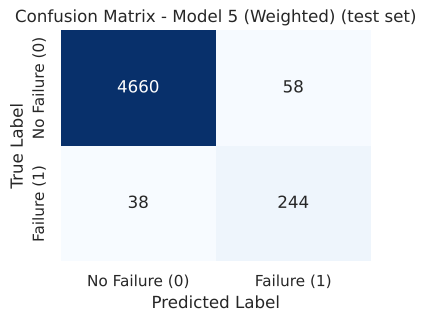

In [32]:
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt="g", cmap="Blues", cbar=False,
            xticklabels=["No Failure (0)", "Failure (1)"], yticklabels=["No Failure (0)", "Failure (1)"])
plt.xlabel("Predicted Label"); plt.ylabel("True Label")
plt.title(f"Confusion Matrix - {best_name} (test set)")
plt.show()

## Conclusion

**Objective.** Predict wind-turbine generator failures early enough to repair them, using 40 ciphered sensor readings. Missing a failure (replacement) is the costliest error, so recall on failures was the priority, with precision and F2 as secondary criteria.

**What was done.** Twelve neural networks were compared: six architectures (one or two hidden layers, SGD or Adam, dropout, batch normalisation) each trained with and without class weights. Missing values in V1 and V2 were filled with the training median, and imputation and scaling were fitted on the training split only. All models used the same seed, 50 epochs and batch size 64, and were scored the same way on the training and validation sets. The model was chosen on the validation set (highest F2); the test set was used once.

**Findings.**
- Class weights raised validation recall for every architecture (Model 0: 0.31 to 0.87, Model 3: 0.75 to 0.88, Model 4: 0.86 to 0.90, Model 5: 0.81 to 0.91) and lowered precision in every case. The simplest model lost the most (Model 0: 0.88 to 0.35); Models 3 and 5 lost the least (0.99 to 0.87 and 0.97 to 0.85).
- **Model 5 (Weighted)** (two hidden layers of 28 and 14 units, batch normalisation, dropout 0.05, class weights) had the best validation F2 (0.897) with recall 0.910 and precision 0.851. Its training and validation scores are almost identical, so there is no sign of overfitting.
- The unweighted Model 4 (batch normalisation only) is a close alternative: slightly better validation F1 (0.915) and much higher precision (0.979) with recall 0.859. The choice between them depends on the real cost ratio: the cost table above shows how many extra false alarms Model 5 (Weighted) accepts to miss fewer failures. If inspections are expensive compared with replacements, Model 4 is the better pick.

**Test result (Model 5 Weighted, 5,000 turbines, 282 failures).** It found 244 of 282 failures (recall 86.5%) and missed 38; of 302 failure alerts, 244 were real (precision 80.8%) and 58 were false alarms; accuracy was 98.1% and F1 0.836. Validation recall was 91.0%, so test recall is about 4.5 points lower. With only 282 test failures a single run can vary by a few points, so treat roughly 86-91% as the likely range, not a precise figure.

**Caveats and next steps.**
- The decision threshold is 0.5; tuning it on the validation set (or a cost curve once real repair / replacement / inspection costs are known) could trade recall against precision more precisely than class weights alone.
- Results come from a single seed and a single train/validation split; repeating with several seeds or cross-validation would show how stable the ranking is.
- The data are ciphered, so the model cannot say *which* physical factor drives a failure.

**Recommendation.** Model 5 (Weighted) is a sound choice when missed failures are much more expensive than inspections. Confirm the cost ratio with ReneWind and re-check the threshold before deployment.